In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from pathlib import Path

from pypuf.simulation import XORArbiterPUF

from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

PROJECT_DIR = Path.home() / "University" / "System_Software_Security"

DATASET_DIR = PROJECT_DIR / "03_Datasets"
RESULTS_DIR = PROJECT_DIR / "04_Results"
GRAPHS_DIR = PROJECT_DIR / "05_Graphs"

print("XOR-PUF experiment environment ready!")

XOR-PUF experiment environment ready!


In [3]:
N = 64
NUM_CRPS = 20000

XOR_COUNTS = [1, 2, 3, 4]

PUF_SEED = 42

pufs = {}

for k in XOR_COUNTS:

    puf = XORArbiterPUF(
        n=N,
        k=k,
        seed=PUF_SEED,
        noisiness=0
    )

    pufs[k] = puf

    print(f"Created {k}-XOR Arbiter PUF successfully!")

Created 1-XOR Arbiter PUF successfully!
Created 2-XOR Arbiter PUF successfully!
Created 3-XOR Arbiter PUF successfully!
Created 4-XOR Arbiter PUF successfully!


In [4]:
rng = np.random.default_rng(42)

# Generate common challenges for all PUF configurations
challenges = rng.choice(
    [-1, 1],
    size=(NUM_CRPS, N)
)

xor_datasets = {}

for k, puf in pufs.items():

    responses = np.asarray(
        puf.eval(challenges)
    ).reshape(-1)

    challenge_strings = [
        ''.join('1' if bit == 1 else '0' for bit in challenge)
        for challenge in challenges
    ]

    response_values = [
        1 if response == 1 else 0
        for response in responses
    ]

    dataset = pd.DataFrame({
        "challenge": challenge_strings,
        "response": response_values
    })

    xor_datasets[k] = dataset

    output_file = DATASET_DIR / f"xor_puf_k{k}_64bit.csv"

    dataset.to_csv(output_file, index=False)

    print(f"{k}-XOR PUF: {len(dataset)} CRPs generated")

1-XOR PUF: 20000 CRPs generated
2-XOR PUF: 20000 CRPs generated
3-XOR PUF: 20000 CRPs generated
4-XOR PUF: 20000 CRPs generated


In [5]:
xor_results = []

for k, dataset in xor_datasets.items():

    print(f"\nRunning experiments for {k}-XOR PUF")

    # Restore 64-bit challenge strings
    X_raw = np.array([
        [int(bit) for bit in challenge]
        for challenge in dataset["challenge"]
    ])

    y = dataset["response"].to_numpy()

    # Bipolar conversion
    X_bipolar = np.where(X_raw == 1, 1, -1)

    # Arbiter PUF feature transformation
    X_phi = np.flip(
        np.cumprod(
            np.flip(X_bipolar, axis=1),
            axis=1
        ),
        axis=1
    )

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X_raw,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    X_phi_train, X_phi_test, _, _ = train_test_split(
        X_phi,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    models = [
        ("LR Raw", X_train, X_test,
         LogisticRegression(max_iter=3000, random_state=42)),

        ("LR Transformed", X_phi_train, X_phi_test,
         LogisticRegression(max_iter=3000, random_state=42)),

        ("MLP Raw", X_train, X_test,
         make_pipeline(
             StandardScaler(),
             MLPClassifier(
                 hidden_layer_sizes=(128, 64),
                 max_iter=300,
                 early_stopping=True,
                 random_state=42
             )
         )),

        ("MLP Transformed", X_phi_train, X_phi_test,
         make_pipeline(
             StandardScaler(),
             MLPClassifier(
                 hidden_layer_sizes=(128, 64),
                 max_iter=300,
                 early_stopping=True,
                 random_state=42
             )
         ))
    ]

    for name, Xtr, Xte, model in models:

        start = time.perf_counter()

        model.fit(Xtr, y_train)

        elapsed = time.perf_counter() - start

        predictions = model.predict(Xte)

        accuracy = accuracy_score(y_test, predictions)

        xor_results.append({
            "XOR_Count": k,
            "Model": name,
            "Accuracy": accuracy * 100,
            "Training_Time": elapsed
        })

        print(
            f"{name}: {accuracy * 100:.2f}% "
            f"| Training: {elapsed:.4f}s"
        )


Running experiments for 1-XOR PUF
LR Raw: 55.43% | Training: 0.0568s
LR Transformed: 99.65% | Training: 0.0058s
MLP Raw: 50.58% | Training: 0.7307s
MLP Transformed: 97.72% | Training: 0.5509s

Running experiments for 2-XOR PUF
LR Raw: 56.20% | Training: 0.0053s
LR Transformed: 50.80% | Training: 0.0020s
MLP Raw: 54.65% | Training: 0.4150s
MLP Transformed: 95.73% | Training: 0.7444s

Running experiments for 3-XOR PUF
LR Raw: 50.52% | Training: 0.0047s
LR Transformed: 58.17% | Training: 0.0022s
MLP Raw: 50.25% | Training: 0.7612s
MLP Transformed: 84.42% | Training: 1.4680s

Running experiments for 4-XOR PUF
LR Raw: 51.75% | Training: 0.0070s
LR Transformed: 50.10% | Training: 0.0020s
MLP Raw: 51.32% | Training: 0.4015s
MLP Transformed: 54.05% | Training: 0.6866s


In [6]:
xor_results_df = pd.DataFrame(xor_results)

xor_results_df.to_csv(
    RESULTS_DIR / "xor_puf_ml_results.csv",
    index=False
)

display(xor_results_df)

,XOR_Count,Model,Accuracy,Training_Time
0,1,LR Raw,55.425,0.056833
1,1,LR Transformed,99.650,0.005825
2,1,MLP Raw,50.575,0.730705
3,1,MLP Transformed,97.725,0.550896
4,2,LR Raw,56.200,0.005325
5,2,LR Transformed,50.800,0.002049
6,2,MLP Raw,54.650,0.414979
7,2,MLP Transformed,95.725,0.744429
8,3,LR Raw,50.525,0.004709
9,3,LR Transformed,58.175,0.002248


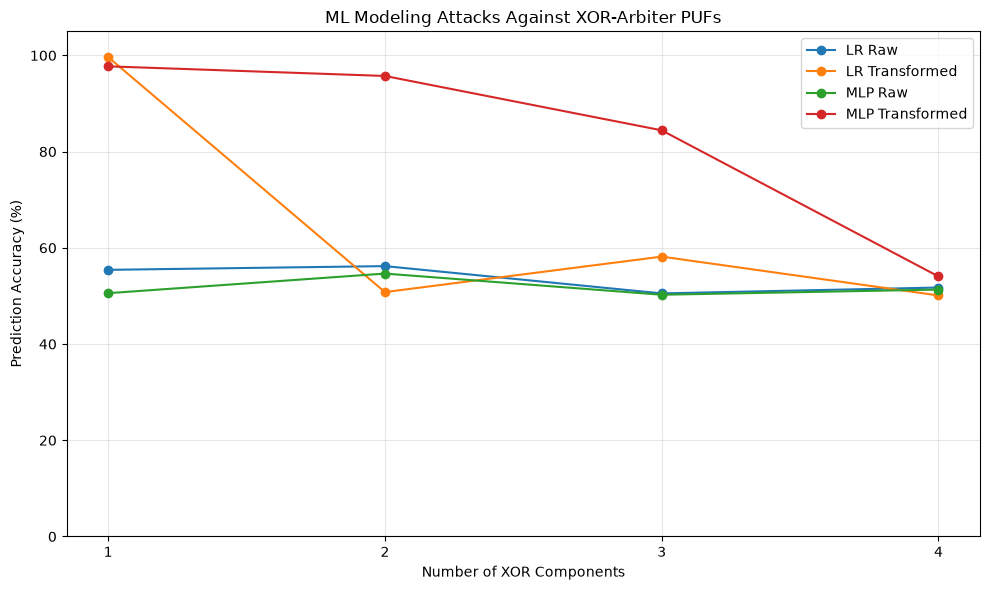

In [7]:
plt.figure(figsize=(10, 6))

for model_name in xor_results_df["Model"].unique():

    subset = xor_results_df[
        xor_results_df["Model"] == model_name
    ]

    plt.plot(
        subset["XOR_Count"],
        subset["Accuracy"],
        marker="o",
        label=model_name
    )

plt.xlabel("Number of XOR Components")
plt.ylabel("Prediction Accuracy (%)")

plt.title("ML Modeling Attacks Against XOR-Arbiter PUFs")

plt.xticks(XOR_COUNTS)
plt.ylim(0, 105)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPHS_DIR / "xor_puf_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Experiment 5: Reproducibility Across Independent PUF Seeds

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from pypuf.simulation import XORArbiterPUF

from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

from pathlib import Path

# Project folders
PROJECT_DIR = Path.home() / "University" / "System_Software_Security"

RESULTS_DIR = PROJECT_DIR / "04_Results"
GRAPHS_DIR = PROJECT_DIR / "05_Graphs"

RESULTS_DIR.mkdir(exist_ok=True)
GRAPHS_DIR.mkdir(exist_ok=True)

# Experiment configuration
N = 64
NUM_CRPS = 20000

XOR_COUNTS = [1, 2, 3, 4]
PUF_SEEDS = [101, 202, 303]

# Generate one fixed challenge set for fair comparison
challenge_rng = np.random.default_rng(42)

challenges_rep = challenge_rng.choice(
    [-1, 1],
    size=(NUM_CRPS, N)
)

# Convert challenges to binary features
X_raw_rep = np.where(challenges_rep == 1, 1, 0)

# Arbiter feature transformation
X_phi_rep = np.flip(
    np.cumprod(
        np.flip(challenges_rep, axis=1),
        axis=1
    ),
    axis=1
)

# Use exactly the same training and test indices
split_rng = np.random.default_rng(42)

indices = split_rng.permutation(NUM_CRPS)

train_indices = indices[:16000]
test_indices = indices[16000:]

X_train_raw = X_raw_rep[train_indices]
X_test_raw = X_raw_rep[test_indices]

X_train_phi = X_phi_rep[train_indices]
X_test_phi = X_phi_rep[test_indices]

print("Challenge dataset prepared!")
print("Training samples:", len(train_indices))
print("Testing samples:", len(test_indices))
print("PUF seeds:", PUF_SEEDS)
print("XOR configurations:", XOR_COUNTS)

Challenge dataset prepared!
Training samples: 16000
Testing samples: 4000
PUF seeds: [101, 202, 303]
XOR configurations: [1, 2, 3, 4]


In [9]:
repeated_results = []

for seed in PUF_SEEDS:

    print("\n" + "=" * 55)
    print(f"TESTING PUF SEED: {seed}")
    print("=" * 55)

    for k in XOR_COUNTS:

        print(f"\nTesting {k}-XOR PUF | Seed {seed}")

        # Create independent PUF instance
        puf = XORArbiterPUF(
            n=N,
            k=k,
            seed=seed,
            noisiness=0
        )

        # Generate responses for the common challenges
        responses = np.asarray(
            puf.eval(challenges_rep)
        ).reshape(-1)

        y = np.where(responses == 1, 1, 0)

        y_train = y[train_indices]
        y_test = y[test_indices]

        print("Training response distribution:",
              np.bincount(y_train))

        # Define four models
        models = [
            (
                "LR Raw",
                X_train_raw,
                X_test_raw,
                LogisticRegression(
                    max_iter=3000,
                    random_state=42
                )
            ),
            (
                "LR Transformed",
                X_train_phi,
                X_test_phi,
                LogisticRegression(
                    max_iter=3000,
                    random_state=42
                )
            ),
            (
                "MLP Raw",
                X_train_raw,
                X_test_raw,
                make_pipeline(
                    StandardScaler(),
                    MLPClassifier(
                        hidden_layer_sizes=(128, 64),
                        max_iter=300,
                        early_stopping=True,
                        n_iter_no_change=15,
                        random_state=42
                    )
                )
            ),
            (
                "MLP Transformed",
                X_train_phi,
                X_test_phi,
                make_pipeline(
                    StandardScaler(),
                    MLPClassifier(
                        hidden_layer_sizes=(128, 64),
                        max_iter=300,
                        early_stopping=True,
                        n_iter_no_change=15,
                        random_state=42
                    )
                )
            )
        ]

        # Train and evaluate each model
        for model_name, Xtr, Xte, model in models:

            start = time.perf_counter()

            model.fit(Xtr, y_train)

            elapsed = time.perf_counter() - start

            predictions = model.predict(Xte)

            accuracy = accuracy_score(
                y_test,
                predictions
            ) * 100

            repeated_results.append({
                "PUF_Seed": seed,
                "XOR_Count": k,
                "Model": model_name,
                "Accuracy": accuracy,
                "Training_Time": elapsed
            })

            print(
                f"{model_name}: {accuracy:.2f}% "
                f"| {elapsed:.4f}s"
            )

print("\nAll repeated experiments completed!")


TESTING PUF SEED: 101

Testing 1-XOR PUF | Seed 101
Training response distribution: [8014 7986]
LR Raw: 52.38% | 0.0095s
LR Transformed: 99.60% | 0.0079s
MLP Raw: 51.52% | 0.4660s
MLP Transformed: 97.78% | 1.2618s

Testing 2-XOR PUF | Seed 101
Training response distribution: [8086 7914]
LR Raw: 53.90% | 0.0037s
LR Transformed: 49.93% | 0.0019s
MLP Raw: 52.15% | 0.4823s
MLP Transformed: 96.12% | 0.9017s

Testing 3-XOR PUF | Seed 101
Training response distribution: [7976 8024]
LR Raw: 50.00% | 0.0038s
LR Transformed: 51.65% | 0.0018s
MLP Raw: 50.68% | 0.6145s
MLP Transformed: 81.03% | 2.3573s

Testing 4-XOR PUF | Seed 101
Training response distribution: [8220 7780]
LR Raw: 50.18% | 0.0040s
LR Transformed: 50.58% | 0.0018s
MLP Raw: 50.35% | 0.6181s
MLP Transformed: 52.65% | 0.6893s

TESTING PUF SEED: 202

Testing 1-XOR PUF | Seed 202
Training response distribution: [8029 7971]
LR Raw: 50.00% | 0.0039s
LR Transformed: 99.65% | 0.0050s
MLP Raw: 50.95% | 0.9357s
MLP Transformed: 97.78% | 0.

In [10]:
repeated_df = pd.DataFrame(repeated_results)

# Save every individual run
repeated_df.to_csv(
    RESULTS_DIR / "xor_independent_seed_results.csv",
    index=False
)

display(repeated_df)

print("Individual experiment results saved!")

,PUF_Seed,XOR_Count,Model,Accuracy,Training_Time
0,101,1,LR Raw,52.375,0.009481
1,101,1,LR Transformed,99.600,0.007876
2,101,1,MLP Raw,51.525,0.466020
3,101,1,MLP Transformed,97.775,1.261762
4,101,2,LR Raw,53.900,0.003747
5,101,2,LR Transformed,49.925,0.001918
6,101,2,MLP Raw,52.150,0.482300
7,101,2,MLP Transformed,96.125,0.901717
8,101,3,LR Raw,50.000,0.003768
9,101,3,LR Transformed,51.650,0.001813


Individual experiment results saved!


In [11]:
summary_df = (
    repeated_df
    .groupby(["XOR_Count", "Model"])["Accuracy"]
    .agg(["mean", "std"])
    .reset_index()
)

summary_df = summary_df.rename(columns={
    "mean": "Mean_Accuracy",
    "std": "Std_Accuracy"
})

print("AVERAGE RESULTS ACROSS THREE PUF SEEDS")

display(
    summary_df.round(2)
)

summary_df.to_csv(
    RESULTS_DIR / "xor_independent_seed_summary.csv",
    index=False
)

AVERAGE RESULTS ACROSS THREE PUF SEEDS


,XOR_Count,Model,Mean_Accuracy,Std_Accuracy
0,1,LR Raw,51.03,1.22
1,1,LR Transformed,99.66,0.06
2,1,MLP Raw,51.23,0.29
3,1,MLP Transformed,97.72,0.10
4,2,LR Raw,54.33,1.16
5,2,LR Transformed,51.12,1.36
6,2,MLP Raw,53.81,1.63
7,2,MLP Transformed,95.72,0.69
8,3,LR Raw,50.19,0.44
9,3,LR Transformed,53.98,4.24


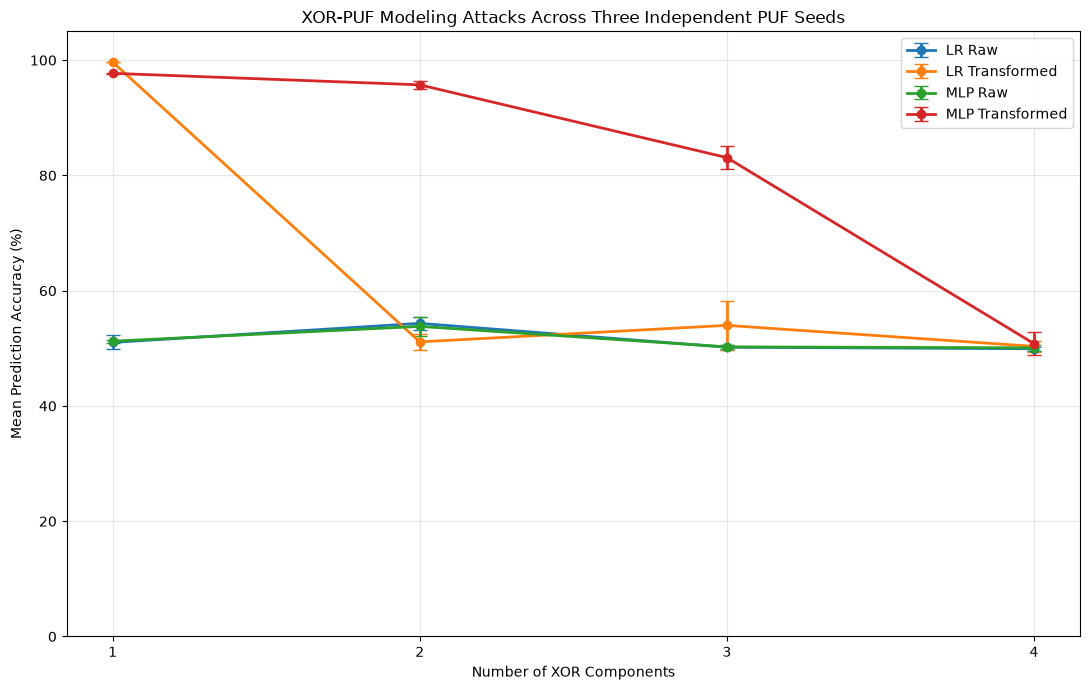

In [12]:
plt.figure(figsize=(11, 7))

for model_name in summary_df["Model"].unique():

    subset = summary_df[
        summary_df["Model"] == model_name
    ].sort_values("XOR_Count")

    plt.errorbar(
        subset["XOR_Count"],
        subset["Mean_Accuracy"],
        yerr=subset["Std_Accuracy"],
        marker="o",
        capsize=5,
        linewidth=2,
        label=model_name
    )

plt.xlabel("Number of XOR Components")
plt.ylabel("Mean Prediction Accuracy (%)")

plt.title(
    "XOR-PUF Modeling Attacks Across Three Independent PUF Seeds"
)

plt.xticks(XOR_COUNTS)
plt.ylim(0, 105)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    GRAPHS_DIR / "xor_independent_seed_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()